In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset (pastikan URL tidak terpotong atau memiliki spasi yang salah)
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# Inspeksi awal
print("Ukuran Data (Baris, Kolom):", df.shape)
print("\nDaftar Kolom:")
print(df.columns.tolist())

# Tampilkan 5 baris pertama (gunakan print agar tampil di Colab jika di luar baris terakhir)
display(df.head())

Ukuran Data (Baris, Kolom): (1067, 24)

Daftar Kolom:
['Kota', 'Tahun', 'DBH_PAJAK', 'DBH_SDA', 'DBH_Lainnya', 'DAU_Grant', 'DAU_Earmark', 'DAK_Fisik', 'DAK_Nonfisik', 'PAD', 'ICT', 'bm_pendidikan', 'bm_kesehatan', 'bm_perumahan', 'bm_lingkungan', 'bm_ekonomi', 'bm_infrastruktur', 'bm_pariwisata', 'bm_perlindungan_sosial', 'KEMISKINAN', 'PENGANGGURAN', 'KETIMPANGAN', 'IPM', 'PE']


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52


Pembersihan dan Pengecekan Missing Value

In [9]:
df = df.dropna(how="all")

if "Tahun" in df.columns:
    df["Tahun"] = df["Tahun"].astype(int)
    df = df.sort_values(by="Tahun").reset_index(drop=True)

# Tampilkan informasi tipe data dan nilai yang hilang
print("Jumlah Missing Values per Kolom:")
print(df.isnull().sum())

Jumlah Missing Values per Kolom:
Kota                      0
Tahun                     0
DBH_PAJAK                 0
DBH_SDA                   0
DBH_Lainnya               0
DAU_Grant                 0
DAU_Earmark               0
DAK_Fisik                 0
DAK_Nonfisik              0
PAD                       0
ICT                       0
bm_pendidikan             0
bm_kesehatan              0
bm_perumahan              0
bm_lingkungan             0
bm_ekonomi                0
bm_infrastruktur          0
bm_pariwisata             0
bm_perlindungan_sosial    0
KEMISKINAN                0
PENGANGGURAN              0
KETIMPANGAN               0
IPM                       0
PE                        0
dtype: int64


Evaluasi Statistik Data Fiskal

In [10]:
summary = df.describe().T[["mean", "min", "50%", "max", "std"]]
summary.columns = ["Rata-rata", "Minimum", "Median", "Maksimum", "Standar Deviasi"]
print("=== RINGKASAN STATISTIK ===")
print(summary)

if "Pendapatan" in df.columns and "Belanja" in df.columns:
    df["Surplus_Defisit"] = df["Pendapatan"] - df["Belanja"]

    # Cari tahun defisit terbesar
    tahun_defisit_max = df.loc[df["Surplus_Defisit"].idxmin(), "Tahun"]
    print(f"\nDefisit terbesar terjadi pada tahun: {tahun_defisit_max}")

=== RINGKASAN STATISTIK ===
                          Rata-rata  Minimum   Median  Maksimum  \
Tahun                   2019.000000  2014.00  2019.00   2024.00   
DBH_PAJAK                107.905464    11.55    96.72    365.02   
DBH_SDA                   71.138960     5.94    61.83    278.51   
DBH_Lainnya               53.830628     6.19    47.76    166.72   
DAU_Grant                178.029850    22.33   163.55    582.96   
DAU_Earmark              107.452034    12.26    98.52    303.09   
DAK_Fisik                107.783393    12.71    99.41    353.44   
DAK_Nonfisik             106.766401    13.42    95.91    381.84   
PAD                      215.204077    24.06   198.42    686.78   
ICT                       81.898013    60.63    82.03    100.00   
bm_pendidikan            173.794424    51.16   175.67    299.93   
bm_kesehatan             175.776842    50.80   178.70    299.85   
bm_perumahan             174.762071    50.00   174.17    299.46   
bm_lingkungan            172.58788

Grafik Tren Rata-rata Variabel Fiskal

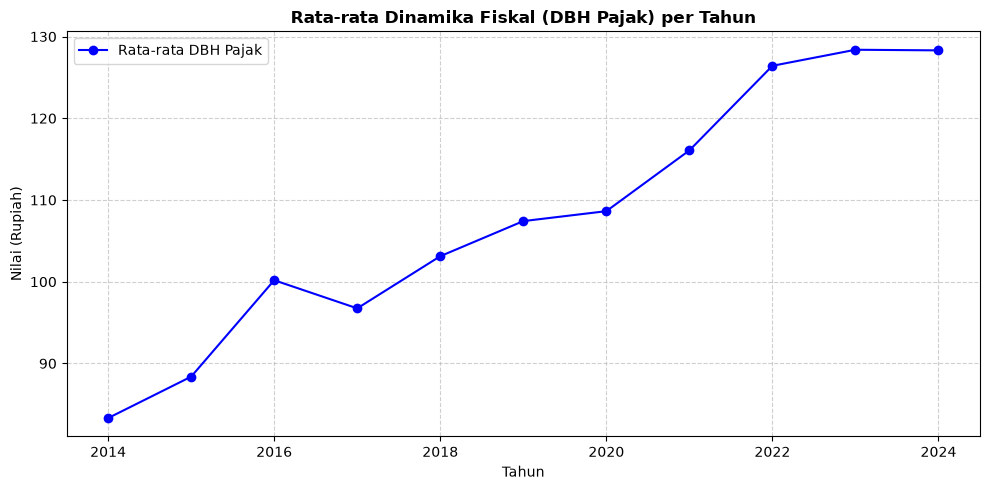

In [8]:
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

df_grouped = df.groupby('Tahun')['DBH_PAJAK'].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(
    df_grouped['Tahun'],
    df_grouped['DBH_PAJAK'],
    marker='o',
    linestyle='-',
    color='b',
    label='Rata-rata DBH Pajak',
)

plt.title(
    'Rata-rata Dinamika Fiskal (DBH Pajak) per Tahun',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tahun')
plt.ylabel('Nilai (Rupiah)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Menampilkan Sampel Data

In [11]:
print(df.head(2))

               Kota  Tahun  DBH_PAJAK  DBH_SDA  DBH_Lainnya  DAU_Grant  \
0   Kota Banda Aceh   2014      77.91    49.42        26.00      96.98   
1  Kota Probolinggo   2014      82.80    44.44        31.76      88.63   

   DAU_Earmark  DAK_Fisik  DAK_Nonfisik     PAD  ...  bm_lingkungan  \
0        47.59      83.94         72.02  153.66  ...         175.78   
1        82.01      44.21         84.87  129.98  ...         214.68   

   bm_ekonomi  bm_infrastruktur  bm_pariwisata  bm_perlindungan_sosial  \
0      253.43            286.18         100.88                  133.54   
1       67.26            273.12         216.76                   92.44   

   KEMISKINAN  PENGANGGURAN  KETIMPANGAN    IPM    PE  
0        5.31          9.79         0.47  65.31  2.82  
1       10.13          9.47         0.30  74.54  3.47  

[2 rows x 24 columns]


Grafik Perbandingan Variabel Sosial-Ekonomi

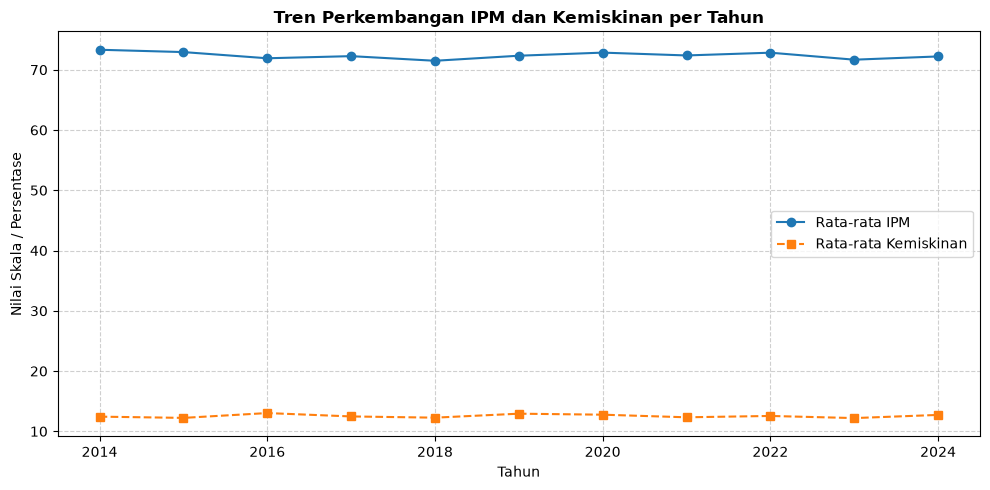

In [12]:
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# 2. Contoh: Ambil rata-rata variabel penting per tahun (misalnya IPM, Kemiskinan, dan PAD)
# Sesuaikan nama kolom jika diperlukan
kolom_fokus = ['Tahun', 'IPM', 'KEMISKINAN', 'PAD']
df_subset = df[kolom_fokus].groupby('Tahun').mean().reset_index()

# 3. Membuat Plot yang Rapi
plt.figure(figsize=(10, 5))

plt.plot(
    df_subset['Tahun'],
    df_subset['IPM'],
    marker='o',
    linestyle='-',
    label='Rata-rata IPM',
)
plt.plot(
    df_subset['Tahun'],
    df_subset['KEMISKINAN'],
    marker='s',
    linestyle='--',
    label='Rata-rata Kemiskinan',
)

# 4. Kustomisasi Tampilan Grafik
plt.title(
    'Tren Perkembangan IPM dan Kemiskinan per Tahun',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tahun')
plt.ylabel('Nilai Skala / Persentase')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

Visualisasi Tren Variabel Fiskal

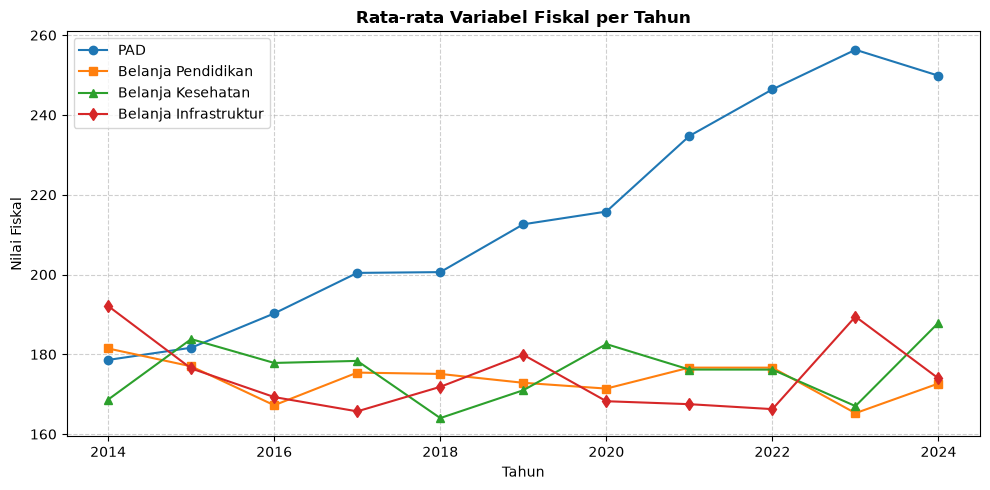

In [13]:
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

df_fiskal = (
    df.groupby("Tahun")[
        ["PAD", "bm_pendidikan", "bm_kesehatan", "bm_infrastruktur"]
    ]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    df_fiskal["Tahun"],
    df_fiskal["PAD"],
    marker="o",
    label="PAD",
    color="#1f77b4",
)
plt.plot(
    df_fiskal["Tahun"],
    df_fiskal["bm_pendidikan"],
    marker="s",
    label="Belanja Pendidikan",
    color="#ff7f0e",
)
plt.plot(
    df_fiskal["Tahun"],
    df_fiskal["bm_kesehatan"],
    marker="^",
    label="Belanja Kesehatan",
    color="#2ca02c",
)
plt.plot(
    df_fiskal["Tahun"],
    df_fiskal["bm_infrastruktur"],
    marker="d",
    label="Belanja Infrastruktur",
    color="#d62728",
)

plt.title(
    "Rata-rata Variabel Fiskal per Tahun", fontsize=12, fontweight="bold"
)
plt.xlabel("Tahun")
plt.ylabel("Nilai Fiskal")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Analisis Peringkat PAD Per Kota

C:\Users\HP\AppData\Local\Temp\ipykernel_5960\1635200800.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


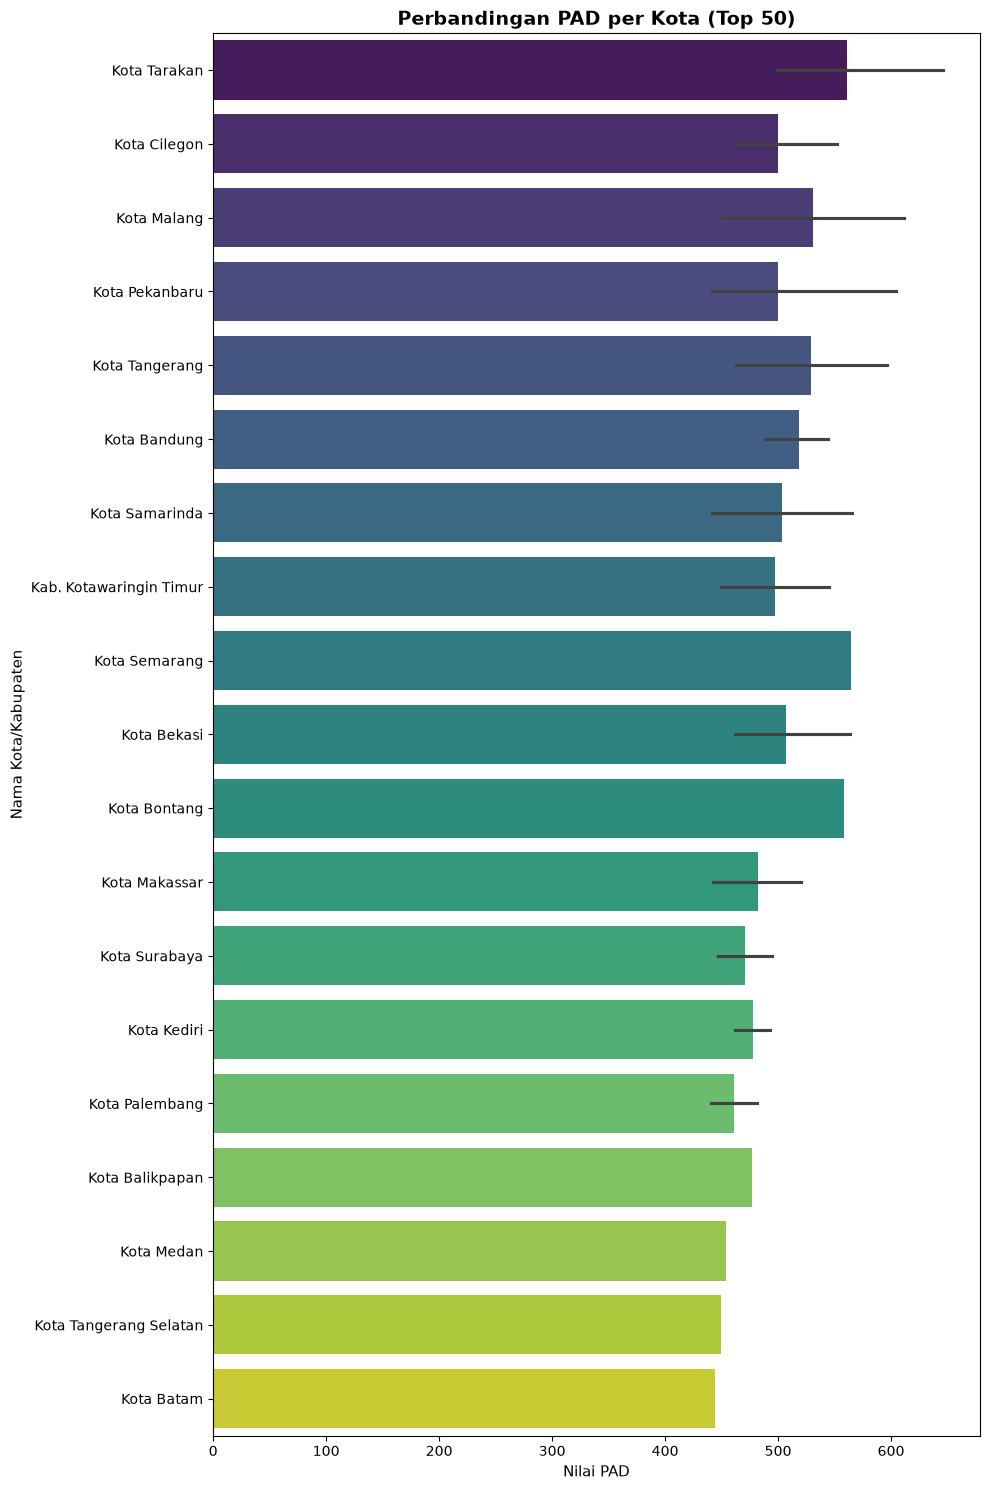

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

top_50 = df.nlargest(50, "PAD") 

plt.figure(figsize=(10, 15)) 

sns.barplot(
    data=top_50,
    x="PAD",         
    y="Kota",        
    palette="viridis" 
)

plt.title("Perbandingan PAD per Kota (Top 50)", fontsize=14, fontweight="bold")
plt.xlabel("Nilai PAD", fontsize=11)
plt.ylabel("Nama Kota/Kabupaten", fontsize=11)

plt.tight_layout()
plt.show()